In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

B = "../data/lake/bronze"   # ".." means one folder up from notebooks/
books = pd.read_csv(f"{B}/books.csv")
customers = pd.read_csv(f"{B}/customers.csv")
orders = pd.read_csv(f"{B}/orders.csv")
reviews = pd.read_csv(f"{B}/reviews.csv")
print(len(books), len(customers), len(orders), len(reviews))

1000 515 3060 1200


In [11]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),          # the kind of data
        "non_null": df.notna().sum(),            # how many cells are filled
        "null_pct": (df.isna().mean() * 100).round(1),   # % of cells that are empty
        "unique": df.nunique(),                  # how many different values
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

profile(customers)

,dtype,non_null,null_pct,unique,example
customer_id,object,515,0.0,500,C0453
full_name,object,515,0.0,91,Muhammad bin Rahman
email,object,490,4.9,467,muhammad.rahman50@gmail.com
phone,object,515,0.0,500,010-7364034
mykad,object,515,0.0,500,780711-04-4427
state,object,515,0.0,22,Melaka
signup_date,object,515,0.0,380,2024-09-11


In [12]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),          # the kind of data
        "non_null": df.notna().sum(),            # how many cells are filled
        "null_pct": (df.isna().mean() * 100).round(1),   # % of cells that are empty
        "unique": df.nunique(),                  # how many different values
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

profile(orders)

,dtype,non_null,null_pct,unique,example
order_id,object,3060,0.0,3000,O00001
customer_id,object,3060,0.0,531,C0105
book_id,object,3060,0.0,963,the-regional-office-is-under-attack_858
quantity,int64,3060,0.0,5,1
order_date,object,3060,0.0,322,2026-04-24


In [13]:
def profile(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),          # the kind of data
        "non_null": df.notna().sum(),            # how many cells are filled
        "null_pct": (df.isna().mean() * 100).round(1),   # % of cells that are empty
        "unique": df.nunique(),                  # how many different values
        "example": df.apply(lambda s: s.dropna().iloc[0] if s.notna().any() else None),
    })

profile(reviews)

,dtype,non_null,null_pct,unique,example
review_id,object,1200,0.0,1200,R00001
customer_id,object,1200,0.0,451,C0352
book_id,object,1200,0.0,699,hollow-city-miss-peregrines-peculiar-children-...
stars,int64,1200,0.0,5,5
review_text,object,1163,3.1,222,The plot was boring and predictable.
review_date,object,1200,0.0,240,2026-08-20


In [14]:
checks = {
    "customers: duplicate rows": customers.duplicated().sum(),
    "customers: missing email": customers["email"].isna().sum(),
    "orders: duplicate order_id": orders["order_id"].duplicated().sum(),
    "orders: quantity <= 0": (orders["quantity"] <= 0).sum(),
    "orders: date not YYYY-MM-DD": pd.to_datetime(
        orders["order_date"], format="%Y-%m-%d", errors="coerce").isna().sum(),
    "orders: unknown customer_id": (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "orders: unknown book_id": (~orders["book_id"].isin(books["book_id"])).sum(),
    "reviews: stars outside 1-5": (~reviews["stars"].between(1, 5)).sum(),
    "reviews: phone number in text": reviews["review_text"].str.contains(
        r"01\d-?\d{7}|\+601", na=False).sum(),
}
pd.Series(checks, name="issues").to_frame()

,issues
customers: duplicate rows,15
customers: missing email,25
orders: duplicate order_id,60
orders: quantity <= 0,33
orders: date not YYYY-MM-DD,101
orders: unknown customer_id,32
orders: unknown book_id,0
reviews: stars outside 1-5,0
reviews: phone number in text,15


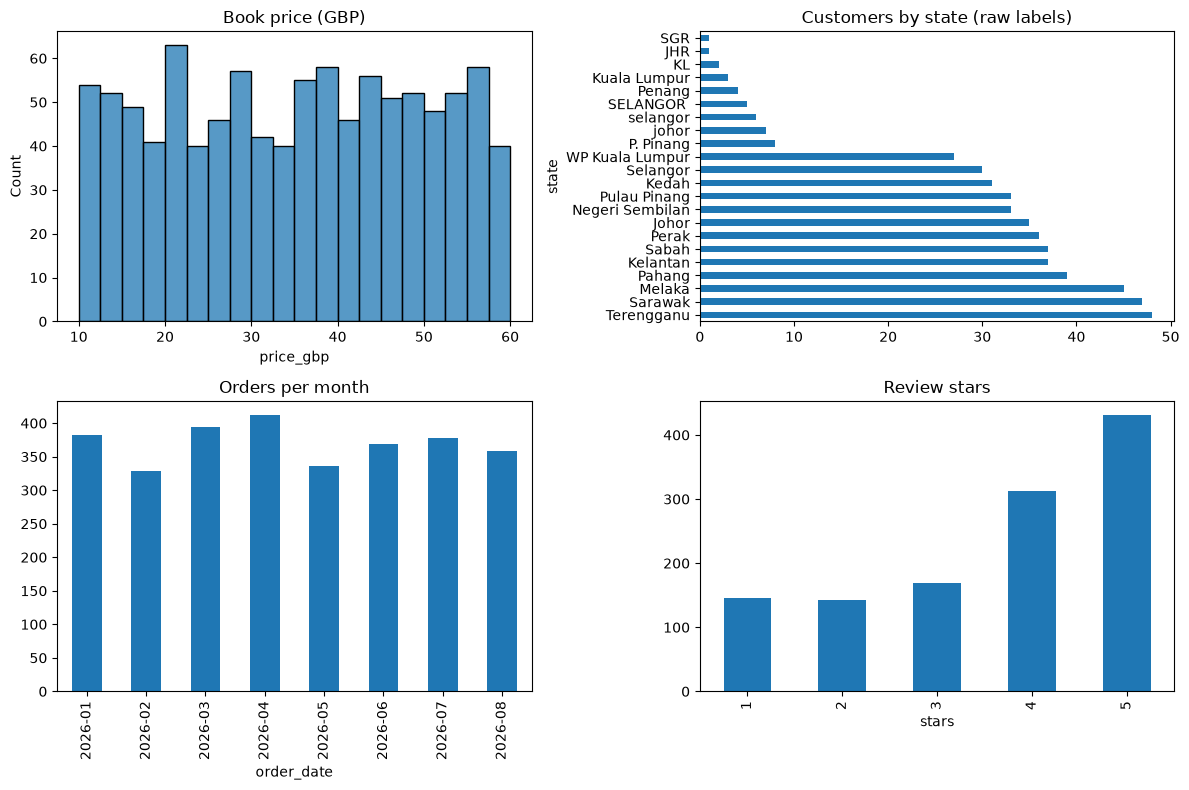

In [15]:
books["price_gbp"] = books["price_raw"].str.replace("£", "", regex=False).astype(float)
orders_ok = orders.assign(order_date=pd.to_datetime(
    orders["order_date"], format="%Y-%m-%d", errors="coerce"))

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
sns.histplot(books["price_gbp"], bins=20, ax=axes[0, 0]).set_title("Book price (GBP)")
customers["state"].value_counts().plot.barh(ax=axes[0, 1], title="Customers by state (raw labels)")
orders_ok.groupby(orders_ok["order_date"].dt.to_period("M")).size().plot.bar(
    ax=axes[1, 0], title="Orders per month")
reviews["stars"].value_counts().sort_index().plot.bar(ax=axes[1, 1], title="Review stars")
plt.tight_layout()
plt.show()

In [16]:
print(list(books.columns))

['book_id', 'title', 'category', 'price_raw', 'rating_raw', 'availability', 'url', 'ingested_at', 'price_gbp']


| Dimension | Table.column | Check | Issues found | Fix planned for Lab 5 |
|---|---|---|---|---|
| Uniqueness | customers | duplicate rows | 15 | drop exact duplicates |
| Completeness | customers.email | missing values | 26| fill with "unknown" or flag |
| Validity | orders.quantity | quantity <= 0 | 60 | remove or correct rows |
| Consistency | customers.state | several labels per state | 5 | standardise to one label per state |
| Validity | orders.order_date | mixed date formats | 97 | convert to YYYY-MM-DD |
| Integrity | orders.customer_id | unknown customer | 0 | remove or flag orphan orders |
| Privacy | customers, reviews.review_text | personal data present | 23 | mask or remove personal data |